# Modern Makine Öğrenmesi Mimarisi Geliştirme
## Hafta 6 — Hiperparametre Optimizasyonu ve Deney Takibi

Geçen hafta bir modelin başarısını hangi metriklerle ölçebileceğimi gördüm. Bu hafta yeni bir soruya geçiyorum:

> Aynı modelin farklı ayarlarını denediğimde hangisini seçmeliyim ve yaptığım bütün denemeleri nasıl düzenli biçimde saklamalıyım?

Bu sorunun ilk yarısını **hiperparametre optimizasyonu**, ikinci yarısını **deney takibi** ile çözeceğim.

### Bu haftanın büyük resmi

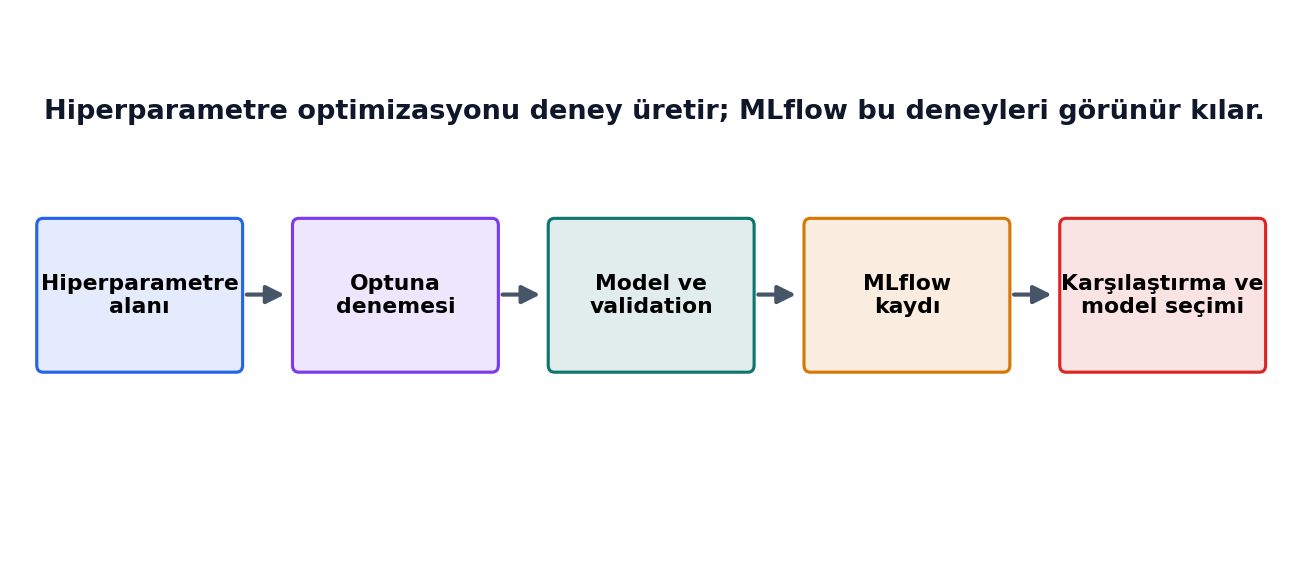

Bu akışın iki tarafı birbirini tamamlar:

- Optuna benim için farklı model ayarları dener.
- MLflow her denemede ne yaptığımı ve hangi sonucu aldığımı kaydeder.
- En sonda yalnızca en yüksek skora değil, bütün deney geçmişine bakarak karar veririm.

## Dersin hedefleri

Bu dersin sonunda:

- parametre ile hiperparametre arasındaki farkı açıklayabileceğim,
- modelin neden ayara ihtiyaç duyduğunu anlayabileceğim,
- train, validation, test ve cross-validation kavramlarını model seçimi açısından yorumlayabileceğim,
- Manual Search, Grid Search, Random Search ve Optuna arasındaki farkı anlatabileceğim,
- Optuna'daki study, trial, objective, sampler ve pruning kavramlarını ayırt edebileceğim,
- MLflow ile parametre, metrik, model ve grafikleri kaydedebileceğim,
- en iyi skorlu model ile production için en uygun modelin neden her zaman aynı olmadığını tartışabileceğim.

## 1. Geçen haftadan bu haftaya

Geçen hafta accuracy, precision, recall, F1, ROC-AUC, MAE ve RMSE gibi metrikleri inceledim. Bir modelin sonucunu nasıl ölçeceğimi artık biliyorum.

Fakat modeli ilk kurduğumda karşıma birçok ayar çıkar:

- Random Forest kaç ağaçtan oluşmalı?
- Ağaçların derinliği ne olmalı?
- Boosting modelinin öğrenme oranı kaç olmalı?
- Bir sinir ağı kaç katman içermeli?

Bu değerleri rastgele seçip yalnızca son skoru yazarsam bilimsel ve tekrar edilebilir bir deney yapmış olmam. Bu nedenle ölçüm bilgisini, sistematik arama ve deney takibiyle birleştirmem gerekir.

## 2. Parametre nedir, hiperparametre nedir?

İki kavramın adı birbirine benzediği için ilk başta karışabilir.

### Parametre

Parametre, modelin eğitim verisine bakarak **kendisinin öğrendiği** değerdir.

- Doğrusal regresyondaki katsayılar
- Logistic Regression'daki ağırlıklar
- Karar ağacındaki bölünme kuralları

Bu değerleri tek tek ben yazmam. Model eğitim sırasında veriden öğrenir.

### Hiperparametre

Hiperparametre, model öğrenmeye başlamadan önce **benim belirlediğim çalışma ayarıdır**.

- Ağacın maksimum derinliği
- Random Forest içindeki ağaç sayısı
- Boosting modelinin öğrenme oranı
- Sinir ağının katman sayısı

Kısaca: Parametre öğrenilen sonuç, hiperparametre öğrenme sürecinin ayarıdır.

### Günlük hayattan bir benzetme

Bir öğrenci sınava hazırlanıyor olsun:

- Öğrencinin çalışırken öğrendiği bilgiler **parametreye** benzer.
- Günde kaç saat çalışacağı, kaç soru çözeceği ve hangi kaynakları kullanacağı **hiperparametreye** benzer.

Öğrenilecek bilgileri önceden tek tek yazmam; fakat öğrenme sürecinin nasıl ilerleyeceğini ayarlayabilirim.

| Model | Öğrendiği parametre | Benim seçtiğim hiperparametre |
|---|---|---|
| Logistic Regression | Katsayılar | Düzenlileştirme gücü `C` |
| Decision Tree | Bölünme kuralları | `max_depth` |
| Random Forest | Her ağacın kuralları | `n_estimators`, `max_features` |
| Gradient Boosting | Ardışık ağaçlar | `learning_rate`, `n_estimators` |

## 3. Neden varsayılan ayarlarla yetinmiyorum?

Kütüphanelerdeki varsayılan değerler modelin kolayca çalışmasını sağlar. Fakat her veri seti aynı değildir:

- Gözlem sayısı farklı olabilir.
- Sınıflar dengesiz olabilir.
- Veri gürültülü olabilir.
- Özellikler arasındaki ilişki basit veya karmaşık olabilir.

Bu nedenle tek bir ayar bütün problemler için en iyi sonucu vermez.

Bir ağacı çok sığ bırakırsam model yeterince öğrenemeyebilir. Çok derin bırakırsam eğitim verisini ezberleyebilir. Aradığım şey en karmaşık model değil, **görmediği veriye en iyi genellenen modeldir**.

### Underfitting ve overfitting

| Durum | Eğitim performansı | Validation performansı | Yorumum |
|---|---|---|---|
| Underfitting | Düşük | Düşük | Model ilişkiyi öğrenemedi |
| Dengeli model | Yüksek | Yüksek | Öğrendiği örüntüyü genelleyebiliyor |
| Overfitting | Çok yüksek | Daha düşük | Eğitim verisini fazla ezberledi |

Hiperparametre optimizasyonunda eğitim skorunu en yüksek yapan ayarı değil, validation performansını güvenilir biçimde yükselten ayarı ararım.

In [ ]:
# Model karmaşıklığı ile eğitim/validation performansının temsili ilişkisi
import numpy as np
import matplotlib.pyplot as plt

complexity = np.arange(1, 16)
train_score = 0.68 + 0.30 * (1 - np.exp(-complexity / 3.2))
validation_score = (
    0.67
    + 0.23 * (1 - np.exp(-complexity / 2.7))
    - 0.0045 * np.maximum(complexity - 7, 0) ** 1.55
)

plt.figure(figsize=(9, 4.5))
plt.plot(complexity, train_score, marker="o", label="Eğitim skoru")
plt.plot(complexity, validation_score, marker="o", label="Validation skoru")
best_index = np.argmax(validation_score)
plt.scatter(complexity[best_index], validation_score[best_index], s=150, color="crimson", zorder=3)
plt.annotate(
    "Genellemenin en güçlü olduğu bölge",
    (complexity[best_index], validation_score[best_index]),
    xytext=(8.5, 0.75),
    arrowprops={"arrowstyle": "->"},
)
plt.xlabel("Model karmaşıklığı")
plt.ylabel("Temsili skor")
plt.title("En karmaşık model her zaman en iyi model değildir")
plt.legend()
plt.show()

### Grafiği nasıl okuyorum?

Başlangıçta model karmaşıklaştıkça hem eğitim hem validation skoru yükseliyor. Bir noktadan sonra eğitim skoru yükselmeye devam ederken validation skoru düşmeye başlıyor.

Bu ayrışma bana modelin yeni örüntüler öğrenmek yerine eğitim verisine özel ayrıntıları ezberlemeye başladığını gösterir.

Hiperparametre optimizasyonunun amacı grafiğin sağ ucuna ulaşmak değil, validation performansının güçlü olduğu bölgeyi bulmaktır.

## 4. Modeli hangi veri üzerinde seçiyorum?

Model geliştirme sırasında veriye üç farklı görev veririm:

### Train verisi

Model ilişkileri bu veriden öğrenir.

### Validation verisi

Farklı hiperparametreleri karşılaştırmak ve model seçmek için kullanırım.

### Test verisi

Bütün seçimler bittikten sonra final performansı ölçmek için kullanırım.

Test sonucuna bakıp tekrar hiperparametre değiştirirsem test verisi artık gerçekten test verisi değildir; model seçiminin parçasına dönüşmüştür.

### Test verisini neden sona saklıyorum?

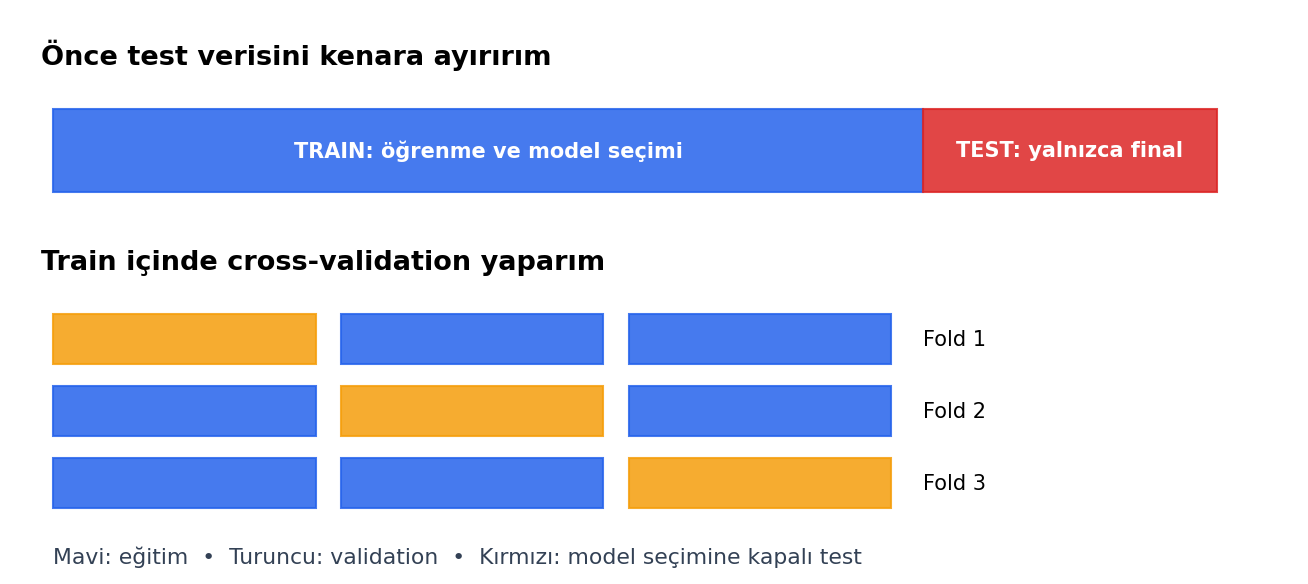

Test verisini bir sınav kâğıdı gibi düşünebilirim. Sorulara çalışırken sınav kâğıdına tekrar tekrar bakarsam aldığım sonuç gerçek öğrenme seviyemi göstermez.

## 5. Cross-validation neden gerekli?

Tek bir validation ayrımı şanslı veya şanssız olabilir. Bazı zor gözlemler bir tarafa yığılmış olabilir.

K-fold cross-validation'da:

1. Train verisini `K` parçaya bölerim.
2. Her turda bir parçayı validation, kalanları eğitim için kullanırım.
3. Modeli `K` kez eğitirim.
4. Validation skorlarının ortalamasını alırım.

Örneğin 5-fold cross-validation kullandığımda her gözlem bir kez validation tarafında yer alır. Böylece model ayarını tek bir bölünmenin şansına göre seçmemiş olurum.

### Ortalama skor tek başına yeterli mi?

İki model düşünelim:

| Model | Fold skorları | Ortalama | Standart sapma |
|---|---|---:|---:|
| A | 0.91, 0.90, 0.92 | 0.91 | Düşük |
| B | 0.84, 0.98, 0.92 | 0.91 | Yüksek |

Ortalamaları aynı olsa da A modeli farklı veri parçalarında daha kararlı görünüyor. Bu nedenle optimizasyon sonucunda yalnızca ortalamayı değil, fold'lar arasındaki değişkenliği de incelerim.

# Bölüm A — Hiperparametre arama yöntemleri

Bir model için olası ayarların tamamına **arama uzayı** derim.

Örneğin Random Forest için:

- `n_estimators`: 100 ile 500 arasında
- `max_depth`: 4, 8, 12 veya sınırsız
- `min_samples_leaf`: 1 ile 8 arasında
- `max_features`: `sqrt`, `log2` veya bütün özellikler

Şimdi bu uzayda hangi noktaları deneyeceğime karar vermem gerekir.

## 6. Manual Search — ayarları kendim denemek

Manual Search'te birkaç değeri tecrübeme göre seçerim.

Örneğin:

1. `max_depth=4` denerim.
2. Model yetersiz öğreniyorsa `max_depth=8` yaparım.
3. Overfitting görürsem `min_samples_leaf` değerini yükseltirim.

İlk keşif için yararlıdır; fakat çok sayıda ayar olduğunda sistematik değildir. Ayrıca sonuçları kaydetmezsem hangi ayarı neden denediğimi kolayca unuturum.

## 7. Grid Search — bütün kombinasyonları denemek

Grid Search'e belirli değer listeleri veririm; yöntem bütün kombinasyonları dener.

Üç hiperparametrenin her biri için beş seçenek verirsem:

$$5 \times 5 \times 5 = 125$$

model eğitirim. Beş hiperparametrenin her biri için beş seçenek verirsem:

$$5^5 = 3125$$

model eğitmem gerekir. Cross-validation da kullanıyorsam gerçek eğitim sayısı daha da büyür.

Grid Search küçük ve ayrık arama uzaylarında anlaşılırdır; ancak boyut arttıkça pahalı hâle gelir.

## 8. Random Search — bütçeyi daha geniş alana yaymak

Random Search bütün kombinasyonları dolaşmak yerine arama uzayından rastgele noktalar seçer.

Bu yöntem ilk bakışta daha basit görünebilir; fakat önemli bir avantajı vardır: Aynı deneme bütçesiyle her hiperparametrenin daha fazla farklı değerini görebilir.

Özellikle model performansını yalnızca birkaç hiperparametre güçlü biçimde etkiliyorsa Random Search, Grid Search'ten daha verimli olabilir.

## 9. Optuna — önceki denemelerden yararlanmak

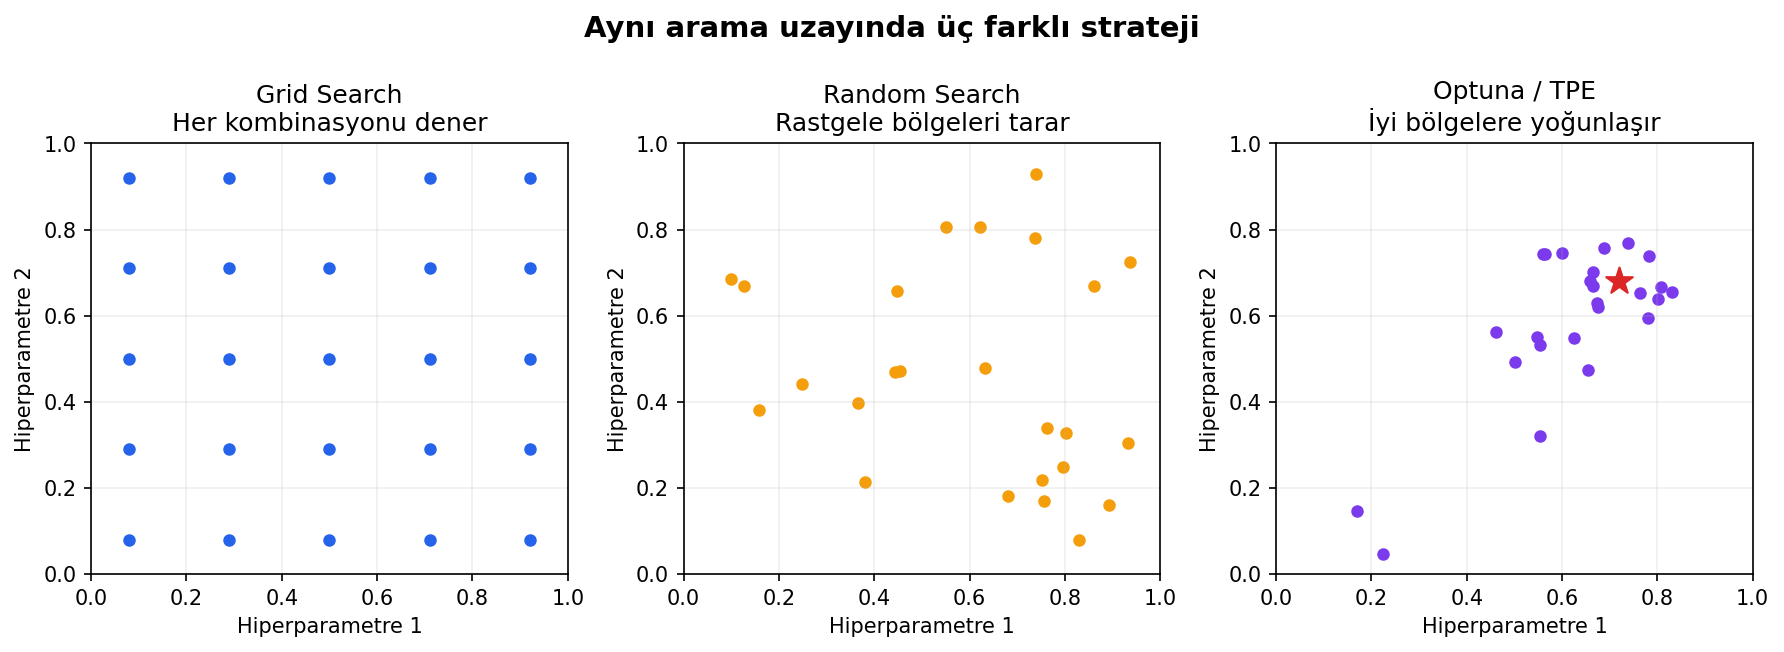

Optuna yalnızca rastgele deneme yapmak zorunda değildir. Önceki denemelerin sonuçlarından yararlanarak iyi görünen bölgelere daha fazla deneme ayırabilir.

Bu, ilk denemede en iyi ayarı bulacağı anlamına gelmez. Başlangıçta keşif yapar; sonuçlar geldikçe aramayı umut vadeden bölgelere doğru yönlendirir.

### Arama yöntemlerini birlikte karşılaştıralım

| Yöntem | Noktaları nasıl seçer? | Güçlü tarafı | Sınırlılığı |
|---|---|---|---|
| Manual Search | Ben seçerim | Basit ve öğretici | Sistematik değil |
| Grid Search | Bütün kombinasyonlar | Kapsamı nettir | Hızla pahalılaşır |
| Random Search | Rastgele seçer | Geniş uzayı tarar | Önceki denemeleri kullanmaz |
| Optuna/TPE | Sonuçlardan yararlanarak seçer | Deneme bütçesini verimli kullanabilir | Doğru objective ve arama uzayı gerekir |

Optuna kötü tanımlanmış bir problemi sihirli biçimde düzeltmez. Yanlış metrik, veri sızıntısı veya anlamsız arama uzayı varsa yalnızca yanlış hedefi daha verimli optimize eder.

# Bölüm B — Optuna'yı koddan önce anlayalım

Optuna kullanırken karşıma beş temel kavram çıkar:

1. Study
2. Trial
3. Objective function
4. Sampler
5. Pruner

Bu kavramları anlamadan yalnızca kodu kopyalarsam, optimizasyonun neden o sonucu verdiğini yorumlamak zorlaşır.

## 10. Study, trial, objective ve sampler

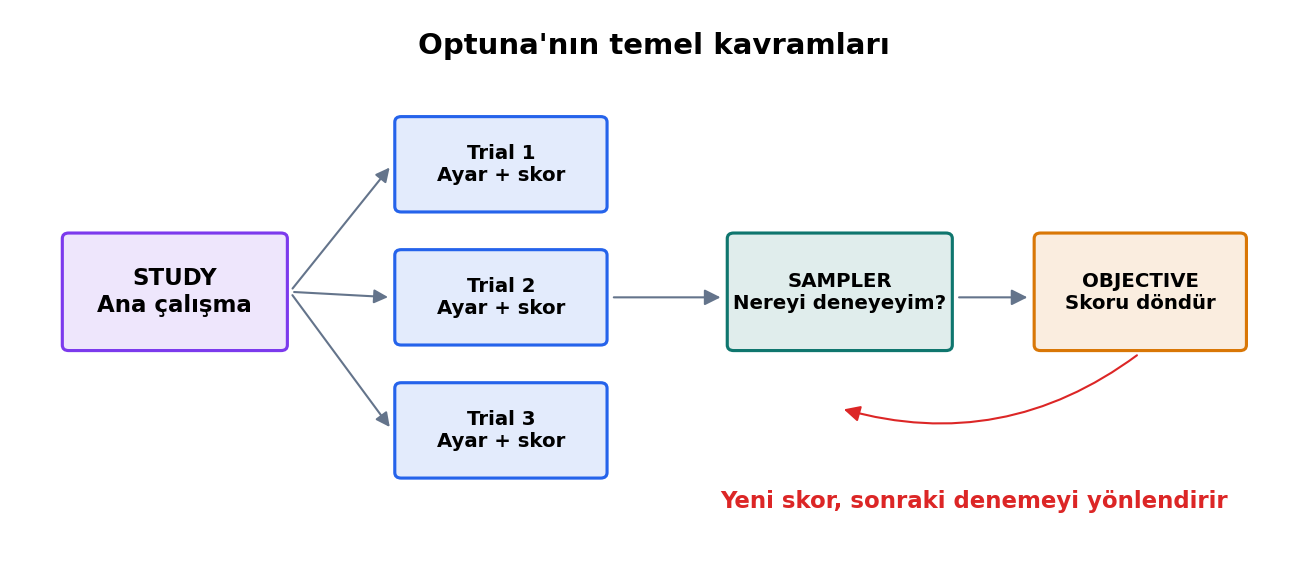

### Study

Bütün optimizasyon çalışmasıdır. “ROC-AUC değerini en yükseğe çıkarmak istiyorum” hedefini study içinde tanımlarım.

### Trial

Tek bir hiperparametre kombinasyonunun denenmesidir. Bir trial; seçilen ayarları ve elde edilen skoru birlikte taşır.

### Objective function

Optuna'nın tekrar tekrar çalıştırdığı fonksiyondur. Parametreleri alır, modeli değerlendirir ve tek bir hedef skor döndürür.

### Sampler

Bir sonraki trial'da hangi değerlerin deneneceğine karar verir. TPE, Optuna'nın yaygın sampler seçeneklerinden biridir.

### Küçük bir trial tablosu

| Trial | `max_depth` | `n_estimators` | CV ROC-AUC | Sonraki karar |
|---:|---:|---:|---:|---|
| 0 | 4 | 100 | 0.91 | Başlangıç denemesi |
| 1 | 12 | 100 | 0.94 | Daha derin ağaç iyi göründü |
| 2 | 12 | 300 | 0.95 | Ağaç sayısı artınca iyileşti |
| 3 | 20 | 300 | 0.93 | Fazla derinlik fayda sağlamadı |

Optuna bu tabloya benzer bir geçmiş oluşturur. Sampler, yeni denemeyi geçmiş sonuçlara göre önerir. Ben ise yalnızca en iyi satırı değil, skorların kararlılığını ve model maliyetini de incelerim.

## 11. Arama uzayını nasıl tanımlarım?

Arama uzayı, Optuna'ya hangi değerleri seçebileceğini söyler.

### Tamsayı aralığı

`n_estimators` gibi değerlerde 100–500 arasında arama yapabilirim.

### Kategorik seçenek

`max_features` için `sqrt`, `log2` veya `None` seçeneklerini verebilirim.

### Logaritmik aralık

Learning rate veya regularization gücü gibi çok farklı büyüklük mertebelerinde değişebilen değerleri logaritmik ölçekte arayabilirim.

Aralığı gereğinden dar tutarsam iyi bölgeyi hiç göremem. Gereğinden geniş tutarsam deneme bütçesinin çoğunu anlamsız bölgelere harcayabilirim.

## 12. Pruning nedir?

Bazı modeller eğitim sırasında ara sonuç üretir. Örneğin boosting modelinin 50. ağacında validation sonucu çok kötü olabilir. Bu trial'ın 500. ağaca kadar devam etmesini beklemek istemeyebilirim.

**Pruning**, umut vermeyen trial'ı erken durdurur ve hesaplama bütçesini başka denemelere ayırır.

- Early stopping, tek bir modelin eğitimini erken durdurur.
- Optuna pruning, bir hiperparametre trial'ını erken sonlandırır.

Random Forest'ı tek seferde eğittiğim uygulamada anlamlı ara sonuç üretmediğim için pruning kullanmayacağım. Boosting ve sinir ağlarında daha doğal bir kullanım alanı vardır.

# Bölüm C — Deney takibi neden gerekli?

On farklı model denediğimi düşünelim. Birkaç gün sonra şu sorular ortaya çıkar:

- En yüksek skoru hangi parametrelerle aldım?
- O denemede hangi veri ayrımını kullandım?
- Model dosyası nerede?
- Sonuç ROC-AUC müydü, F1 mıydı?
- Aynı denemeyi tekrar çalıştırabilir miyim?

Sonuçları yalnızca notebook çıktılarında bırakırsam hücreler farklı sırada çalıştırılabilir, çıktılar silinebilir ve deney bağlamı kaybolabilir. MLflow bu bilgileri düzenli bir deney yapısında tutmama yardım eder.

## 13. MLflow'un temel kavramları

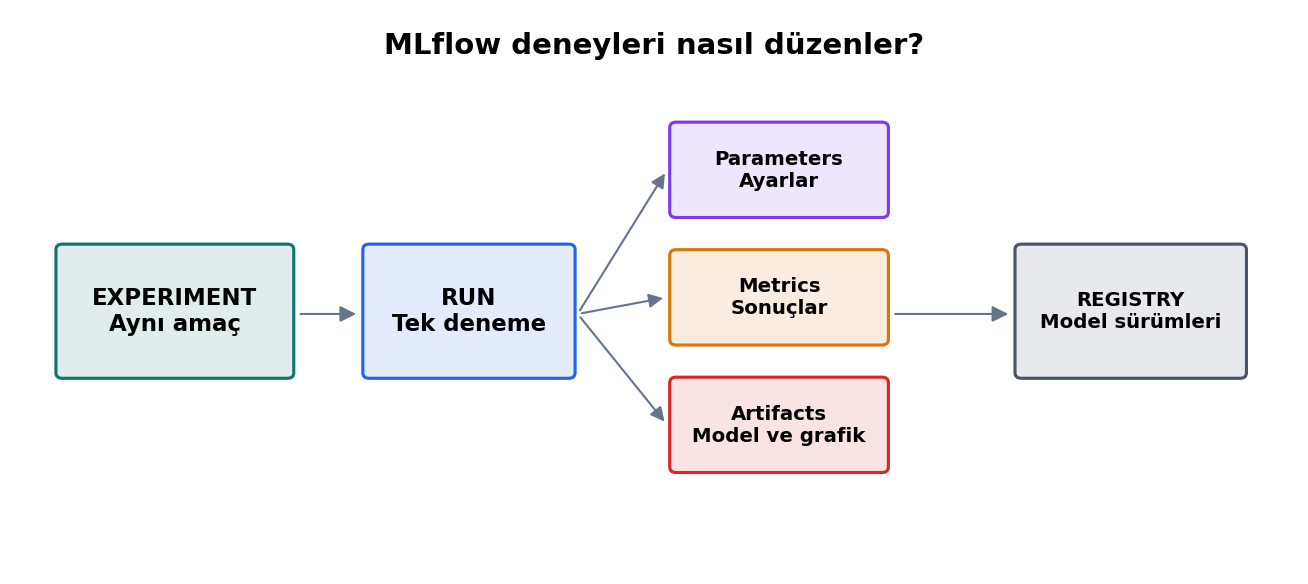

### Experiment

Aynı problem için yaptığım çalışmaların ana klasörü gibi düşünebilirim.

### Run

Tek bir eğitim çalışmasıdır. Bir Optuna trial'ını bir MLflow run'ı olarak kaydedebilirim.

### Parameters

Model ayarlarıdır: `max_depth=8`, `n_estimators=300` gibi.

### Metrics

Sayısal sonuçlardır: `cv_roc_auc=0.95`, `test_f1=0.88` gibi.

### Artifacts

Model dosyası, confusion matrix grafiği, feature importance tablosu veya rapor gibi çıktılardır.

### Model Registry

Kaydettiğim modellerin sürümlerini ve yaşam döngüsünü yönetmeme yardım eder.

## 14. Optuna ve MLflow birlikte nasıl çalışır?

Her Optuna trial'ı için şu döngüyü kurarım:

1. Optuna bir hiperparametre kombinasyonu önerir.
2. Modeli bu ayarlarla eğitirim.
3. Cross-validation skorunu hesaplarım.
4. Parametreleri ve skoru MLflow'a kaydederim.
5. Skoru Optuna'ya döndürürüm.
6. Optuna sonraki trial için yeni ayarlar önerir.

Optuna “sırada neyi deneyelim?” sorusuna; MLflow ise “ne denedik ve ne sonuç aldık?” sorusuna cevap verir.

### Ne kaydetmeliyim?

| Kayıt türü | Örnek | Neden gerekli? |
|---|---|---|
| Parametre | `max_depth=8` | Model ayarını tekrar kurabilmek |
| Validation metriği | `cv_roc_auc_mean=0.95` | Modelleri karşılaştırmak |
| Skor değişkenliği | `cv_roc_auc_std=0.01` | Kararlılığı görmek |
| Veri bilgisi | Veri adı/sürümü | Sonucun hangi veriden geldiğini bilmek |
| Etiket | `stage=hyperparameter_search` | Run'ları gruplamak |
| Artifact | Model ve grafik | Sonucu yeniden kullanmak ve incelemek |

Her şeyi kaydetmek yerine karar vermek için gerekli bağlamı kaydederim. Anlamsız yüzlerce alan, deney ekranını da kullanışsız hâle getirebilir.

# Uygulama — Optuna ve MLflow ile Random Forest

Teorik kavramları kurduktan sonra aynı akışı gerçek bir sınıflandırma problemi üzerinde uygulayacağım.

Notebook'un dışarıdan CSV dosyasına bağımlı olmaması için scikit-learn ile gelen meme kanseri veri setini kullanıyorum.

Her satır bir gözlemi, kolonlar hücre çekirdeği ölçümlerini temsil ediyor. Hedefim kitlenin kötü huylu olup olmadığını tahmin etmek.

> Bu veri yalnızca eğitim amacıyla kullanılmaktadır. Gerçek sağlık uygulamalarında klinik doğrulama, etik, güvenlik ve uzman değerlendirmesi gerekir.

## 15. Ortamı hazırlıyorum

Optuna ve MLflow standart scikit-learn kurulumu içinde gelmeyebilir. Paketler bilgisayarımda yoksa aşağıdaki kurulum hücresini bir kez çalıştırırım. Kurulumdan sonra kernel'i yeniden başlatmam gerekebilir.

In [ ]:
# Paketler kurulu değilse yorum işaretini kaldırıp çalıştırabilirim.
# %pip install -q optuna mlflow

In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

import mlflow
import mlflow.sklearn
import optuna
from mlflow.models import infer_signature

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42

## 16. Veriyi tanıyorum

Model kurmadan önce şu sorulara cevap ararım:

- Kaç gözlem ve özellik var?
- Hedef değişken hangi sınıflardan oluşuyor?
- Sınıflar dengeli mi?
- Eksik değer var mı?
- Hedefin 0 ve 1 anlamı nedir?

Orijinal veri setinde `0=malignant`, `1=benign` olarak tanımlanmıştır. Pozitif sınıfı “kötü huylu” olacak biçimde hedefi yeniden düzenliyorum. Böylece recall gibi metrikleri riskli vakayı yakalama üzerinden yorumlayabilirim.

In [ ]:
dataset = load_breast_cancer(as_frame=True)
X = dataset.data.copy()

# Pozitif sınıf: kötü huylu vaka
y = (dataset.target == 0).astype(int).rename("is_malignant")

df = X.copy()
df["is_malignant"] = y

print(f"Gözlem sayısı : {df.shape[0]}")
print(f"Özellik sayısı: {X.shape[1]}")
print(f"Eksik değer   : {df.isna().sum().sum()}")
display(df.head())

In [ ]:
target_counts = y.value_counts().sort_index()
target_counts.index = ["İyi huylu", "Kötü huylu"]

ax = target_counts.plot(kind="bar", figsize=(7, 4), color=["steelblue", "crimson"])
ax.set(title="Hedef değişken dağılımı", xlabel="Sınıf", ylabel="Gözlem sayısı")
ax.tick_params(axis="x", rotation=0)
plt.show()

display(target_counts.to_frame("gözlem_sayısı"))

### İlk yorumum

İyi huylu vakalar daha fazla olsa da pozitif sınıf tamamen kaybolmuş değildir. Yine de yalnızca accuracy kullanmak istemem.

Bu derste hiperparametre seçimi için ROC-AUC kullanacağım. Final testte ayrıca F1 ve confusion matrix'e bakacağım. Gerçek bir sağlık probleminde özellikle kötü huylu vakayı kaçırma maliyeti nedeniyle recall ve karar eşiği daha ayrıntılı ele alınmalıdır.

## 17. Test verisini ayırıyorum

Test verisini en başta ayırıp optimizasyon sürecinden uzak tutarım. Optuna yalnızca train verisi içindeki cross-validation sonuçlarını görecek.

`stratify=y` kullanarak sınıf oranlarını train ve test tarafında benzer tutuyorum. Cross-validation için de `StratifiedKFold` seçiyorum.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame(
    {
        "Gözlem": [len(X_train), len(X_test)],
        "Pozitif sınıf oranı": [y_train.mean(), y_test.mean()],
    },
    index=["Train", "Test"],
)
split_summary

## 18. Baseline modeli kuruyorum

Optimizasyona başlamadan önce varsayılan ayarlara yakın bir model ölçerim. Buna baseline derim.

Baseline olmadan optimizasyon sonunda aldığım skorun gerçekten iyileşme olup olmadığını bilemem. Belki 50 trial çalıştırmışımdır fakat varsayılan modelden daha iyi sonuç elde edememişimdir.

In [ ]:
baseline_model = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

baseline_scores = cross_val_score(
    baseline_model,
    X_train,
    y_train,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
)

baseline_cv_auc = float(baseline_scores.mean())

print("Fold ROC-AUC değerleri:", np.round(baseline_scores, 4))
print("Ortalama ROC-AUC       :", round(baseline_cv_auc, 4))
print("Standart sapma         :", round(float(baseline_scores.std()), 4))

### Baseline sonucunu nasıl okuyorum?

Fold skorları birbirine yakınsa modelin farklı veri parçalarında daha kararlı davrandığını düşünürüm. Ortalama skor başlangıç noktamdır.

Optimizasyondan sonra yalnızca “en iyi skor kaç?” sorusunu sormayacağım:

- Baseline'a göre ne kadar iyileşti?
- Skor farkı pratik olarak anlamlı mı?
- Model daha karmaşık veya daha yavaş hâle geldi mi?
- Fold'lar arasındaki değişkenlik arttı mı?

## 19. Önce küçük bir manual search yapıyorum

Optuna'ya geçmeden önce üç anlaşılır kombinasyonu elle deniyorum. Böylece hiperparametre değiştiğinde model davranışının nasıl değiştiğini gözlemleyebilirim.

In [ ]:
manual_candidates = [
    {"name": "Sığ ve küçük", "n_estimators": 100, "max_depth": 4, "min_samples_leaf": 2},
    {"name": "Orta", "n_estimators": 250, "max_depth": 8, "min_samples_leaf": 2},
    {"name": "Derin", "n_estimators": 400, "max_depth": None, "min_samples_leaf": 1},
]

manual_results = []

for candidate in manual_candidates:
    model = RandomForestClassifier(
        n_estimators=candidate["n_estimators"],
        max_depth=candidate["max_depth"],
        min_samples_leaf=candidate["min_samples_leaf"],
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    scores = cross_val_score(model, X_train, y_train, scoring="roc_auc", cv=cv, n_jobs=-1)
    manual_results.append(
        {
            **candidate,
            "cv_roc_auc_mean": scores.mean(),
            "cv_roc_auc_std": scores.std(),
        }
    )

pd.DataFrame(manual_results).sort_values("cv_roc_auc_mean", ascending=False)

### Manual search bana ne öğretti?

Üç deneme model karmaşıklığına ilişkin bir fikir verir; fakat bu sonuçlardan “aradığım en iyi ayarı buldum” diyemem.

Çünkü:

- Yalnızca üç nokta denedim.
- Parametreler arasındaki etkileşimleri geniş biçimde taramadım.
- Hangi denemeyi neden yaptığımı elle kaydetmem gerekiyor.

Şimdi bu süreci Optuna ile sistematik, MLflow ile izlenebilir hâle getireceğim.

## 20. MLflow çalışma alanını hazırlıyorum

MLflow kayıtlarını yerel bir SQLite dosyasında tutacağım. Bu dosya notebook'un bulunduğu klasörde oluşur.

Gerçek bir ekip ortamında herkesin erişebildiği merkezi bir tracking server kullanabilirim. Bu derste yerel kurulum, kavramları göstermek için yeterlidir.

In [ ]:
TRACKING_URI = "sqlite:///mlflow_hafta6.db"
EXPERIMENT_NAME = "hafta_6_optuna_mlflow"

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)

print("Tracking URI :", mlflow.get_tracking_uri())
print("Experiment   :", EXPERIMENT_NAME)

## 21. Objective fonksiyonunu kuruyorum

Objective fonksiyonum her trial'da aynı altı adımı uygulayacak:

1. Optuna'dan hiperparametre önerileri alacak.
2. Random Forest modelini oluşturacak.
3. Train verisi içinde cross-validation yapacak.
4. Ortalama ve standart sapmayı hesaplayacak.
5. Parametreleri ve metrikleri MLflow'a kaydedecek.
6. Ortalama ROC-AUC değerini Optuna'ya döndürecek.

Test verisinin bu fonksiyonda bulunmaması özellikle önemlidir.

In [ ]:
def objective(trial):
    # Optuna'nın deneyebileceği arama uzayı
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
        "max_depth": trial.suggest_categorical("max_depth", [4, 6, 8, 12, None]),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 16),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 8),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", None]),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        "random_state": RANDOM_STATE,
        "n_jobs": -1,
    }

    model = RandomForestClassifier(**params)

    # Her trial ayrı bir MLflow run'ı olur.
    with mlflow.start_run(run_name=f"trial_{trial.number:03d}", nested=True):
        mlflow.set_tags(
            {
                "stage": "hyperparameter_search",
                "algorithm": "RandomForestClassifier",
                "optimizer": "Optuna-TPE",
                "dataset": "sklearn_breast_cancer",
            }
        )
        mlflow.log_params({key: str(value) for key, value in params.items()})

        fold_scores = cross_val_score(
            model,
            X_train,
            y_train,
            scoring="roc_auc",
            cv=cv,
            n_jobs=-1,
        )

        mean_auc = float(fold_scores.mean())
        std_auc = float(fold_scores.std())

        mlflow.log_metric("cv_roc_auc_mean", mean_auc)
        mlflow.log_metric("cv_roc_auc_std", std_auc)
        mlflow.log_metric("trial_number", trial.number)

    return mean_auc

### Objective kodunu nasıl okuyorum?

Bu fonksiyon modelin kendisi değildir. Model denemesinin tarifidir.

- `suggest_int`, tamsayı aralığından değer önerir.
- `suggest_categorical`, verdiğim seçeneklerden birini seçer.
- `cross_val_score`, aynı ayarı farklı fold'larda ölçer.
- `log_params`, ayarları MLflow'a yazar.
- `log_metric`, sonuçları MLflow'a yazar.
- `return mean_auc`, Optuna'ya bu trial'ın başarısını bildirir.

Optuna fonksiyonu tekrar tekrar çağırır; her çağrı yeni bir trial üretir.

## 22. Optimizasyonu başlatıyorum

Derste süreyi kontrol etmek için 15 trial çalıştıracağım. Bu sayı evrensel bir doğru değildir.

Gerçek projede trial bütçesini şu faktörlere göre belirlerim:

- Bir modelin eğitim süresi
- Arama uzayının büyüklüğü
- Kullanabildiğim işlem kaynağı
- Yeni trial'ların hâlâ anlamlı iyileşme sağlayıp sağlamaması

TPE sampler'a sabit seed vererek deney akışını daha tekrar edilebilir hâle getiriyorum.

In [ ]:
sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)

study = optuna.create_study(
    direction="maximize",
    sampler=sampler,
    study_name="random_forest_roc_auc",
)

with mlflow.start_run(run_name="optuna_search_parent"):
    mlflow.set_tags(
        {
            "stage": "hyperparameter_search_parent",
            "model_family": "bagging",
            "dataset": "sklearn_breast_cancer",
        }
    )
    mlflow.log_metric("baseline_cv_roc_auc", baseline_cv_auc)

    study.optimize(
        objective,
        n_trials=15,
        show_progress_bar=True,
    )

    mlflow.log_metric("best_cv_roc_auc", float(study.best_value))
    mlflow.log_params(
        {f"best_{key}": str(value) for key, value in study.best_params.items()}
    )

print("En iyi CV ROC-AUC:", round(study.best_value, 4))
display(pd.Series(study.best_params, name="değer").to_frame())

## 23. Trial geçmişini inceliyorum

Optimizasyon tamamlandığında yalnızca `best_value` değerine bakmam. Bütün trial'ları tabloya çevirerek şu soruları sorarım:

- İyi skorlar belirli bir bölgede mi yoğunlaşıyor?
- En iyi skor tek ve sıra dışı bir sonuç mu?
- Trial'lar ilerledikçe iyileşme devam ediyor mu?
- Baseline'a göre fark ne kadar?

In [ ]:
trials_df = study.trials_dataframe()

summary_columns = [
    "number",
    "value",
    "duration",
    "state",
    "params_n_estimators",
    "params_max_depth",
    "params_min_samples_leaf",
]

available_columns = [column for column in summary_columns if column in trials_df.columns]
display(
    trials_df[available_columns]
    .sort_values("value", ascending=False)
    .head(10)
)

In [ ]:
completed = trials_df.dropna(subset=["value"]).sort_values("number").copy()
completed["o_ana_kadarki_en_iyi"] = completed["value"].cummax()

plt.figure(figsize=(9, 4.5))
plt.scatter(completed["number"], completed["value"], alpha=0.8, label="Trial skoru")
plt.plot(
    completed["number"],
    completed["o_ana_kadarki_en_iyi"],
    color="crimson",
    linewidth=2,
    label="O ana kadarki en iyi skor",
)
plt.axhline(baseline_cv_auc, color="gray", linestyle="--", label="Baseline")
plt.xlabel("Trial numarası")
plt.ylabel("CV ROC-AUC")
plt.title("Optimizasyon geçmişi")
plt.legend()
plt.show()

### Optimizasyon grafiğini nasıl yorumluyorum?

Her nokta bir trial'ı gösterir. Kırmızı çizgi o ana kadar bulunan en iyi skordur.

- Çizgi uzun süre değişmiyorsa arama doygunluğa ulaşmış olabilir.
- Skorlar çok dağınıksa arama uzayı geniş veya sonuçlar kararsız olabilir.
- En iyi skor baseline'a çok yakınsa optimizasyonun sağladığı kazanç sınırlı olabilir.

Küçük bir skor artışı büyük bir model ve tahmin maliyeti getiriyorsa production açısından değerli olmayabilir.

## 24. En iyi modeli eğitiyorum

Optuna hiperparametre seçimini tamamladı. Şimdi en iyi ayarlarla bütün train verisi üzerinde final modeli eğiteceğim.

Burada “final model” derken bu notebook içindeki aday modeli kastediyorum. Modelin gerçek production'a çıkması için performans dışında güvenlik, gecikme, veri kalitesi ve yönetişim kontrolleri de gerekir.

In [ ]:
best_model_params = {
    **study.best_params,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}

best_model = RandomForestClassifier(**best_model_params)
best_model.fit(X_train, y_train)

test_probability = best_model.predict_proba(X_test)[:, 1]
test_prediction = best_model.predict(X_test)

test_roc_auc = roc_auc_score(y_test, test_probability)
test_f1 = f1_score(y_test, test_prediction)

print("En iyi CV ROC-AUC:", round(study.best_value, 4))
print("Test ROC-AUC       :", round(test_roc_auc, 4))
print("Test F1            :", round(test_f1, 4))

### CV skoru ile test skoru neden aynı değil?

Cross-validation ortalaması model seçimi sırasında gördüğüm train parçalarından gelir. Test skoru ise tamamen kenarda tuttuğum gözlemlerden gelir.

Küçük bir fark normaldir. Büyük bir düşüş görürsem şu ihtimalleri araştırırım:

- Optimizasyon sürecinde overfitting
- Train ve test dağılımları arasında fark
- Veri sızıntısı
- Çok küçük veya temsil gücü düşük test seti
- Yanlış preprocessing akışı

In [ ]:
print(
    classification_report(
        y_test,
        test_prediction,
        target_names=["İyi huylu", "Kötü huylu"],
    )
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_prediction,
    display_labels=["İyi huylu", "Kötü huylu"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Test confusion matrix")

RocCurveDisplay.from_predictions(y_test, test_probability, ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_title("Test ROC eğrisi")

plt.tight_layout()
plt.show()

## 25. Final modeli MLflow'a kaydediyorum

Arama trial'larında parametreleri ve validation skorlarını kaydettim. Final run'da bunlara ek olarak:

- test metriklerini,
- confusion matrix sayılarını,
- eğitilmiş modeli,
- örnek girdiyi,
- model signature bilgisini

kaydedeceğim.

Signature, modelin beklediği girdi ve ürettiği çıktı yapısını tanımlamaya yardım eder.

In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test, test_prediction).ravel()

signature = infer_signature(
    X_train,
    best_model.predict_proba(X_train),
)

input_example = X_train.head(3)

with mlflow.start_run(run_name="best_random_forest_final") as final_run:
    mlflow.set_tags(
        {
            "stage": "final_evaluation",
            "dataset": "sklearn_breast_cancer",
            "selection_metric": "cv_roc_auc",
            "test_used_for_tuning": "false",
        }
    )

    mlflow.log_params({key: str(value) for key, value in best_model_params.items()})
    mlflow.log_metrics(
        {
            "best_cv_roc_auc": float(study.best_value),
            "test_roc_auc": float(test_roc_auc),
            "test_f1": float(test_f1),
            "test_tn": int(tn),
            "test_fp": int(fp),
            "test_fn": int(fn),
            "test_tp": int(tp),
        }
    )

    model_info = mlflow.sklearn.log_model(
        sk_model=best_model,
        artifact_path="model",
        signature=signature,
        input_example=input_example,
        registered_model_name="Hafta6_RandomForest",
    )

print("Final run ID:", final_run.info.run_id)
print("Model URI   :", model_info.model_uri)

## 26. MLflow arayüzünü açıyorum

Notebook'u kapatmadan ayrı bir terminal açarım ve notebook'un bulunduğu klasörde şu komutu çalıştırırım:

```bash
mlflow ui --backend-store-uri sqlite:///mlflow_hafta6.db --port 5000
```

Ardından tarayıcıdan şu adrese giderim:

```text
http://127.0.0.1:5000
```

Arayüzde experiment'ı seçip run'ları parametre ve metriklerine göre karşılaştırabilirim.

### Arayüzde öğrencilere soracağım sorular

1. En yüksek ortalama ROC-AUC hangi trial'da elde edildi?
2. En iyi ortalamaya sahip run'ın standart sapması nasıl?
3. Birbirine çok yakın skorlar arasında daha basit model var mı?
4. `max_depth` arttıkça skor sürekli yükseliyor mu?
5. Baseline ile en iyi trial arasındaki fark pratik olarak anlamlı mı?
6. Final test skoru CV skorundan neden farklı olabilir?

Bu sorular deney takibini yalnızca “log tutma” işinden çıkarıp karar verme aracına dönüştürür.

## 27. MLflow run'larını Python ile karşılaştırıyorum

MLflow arayüzü dışında sonuçları Python ile de sorgulayabilirim. Aşağıdaki hücre, aynı experiment içindeki run'ları validation ROC-AUC değerine göre sıralar.

In [ ]:
experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["metrics.cv_roc_auc_mean DESC"],
)

columns = [
    "run_id",
    "tags.mlflow.runName",
    "metrics.cv_roc_auc_mean",
    "metrics.cv_roc_auc_std",
    "params.n_estimators",
    "params.max_depth",
    "params.min_samples_leaf",
]

available_columns = [column for column in columns if column in runs.columns]
runs[available_columns].head(10)

## 28. Model Registry ne işe yarar?

Model Registry, modelleri sürümleyip yaşam döngülerini izlememe yardım eder.

Örneğin:

- Sürüm 1: İlk Random Forest
- Sürüm 2: Yeni veriyle eğitilmiş model
- Sürüm 3: Yeni özellikler eklenmiş model

Fakat registry'ye kaydetmek modeli otomatik olarak production'a uygun yapmaz. Registry bir yönetim ve izlenebilirlik aracıdır; kalite onayı değildir.

### Bir modeli production adayı yapmadan önce

- Bağımsız test performansını incelerim.
- Hata türlerini ve iş maliyetini değerlendiririm.
- Veri sızıntısını kontrol ederim.
- Tahmin süresi ve model boyutunu ölçerim.
- Açıklanabilirlik ve adalet kontrollerini yaparım.
- Veri drift'i ve performans izleme planı kurarım.
- Eski modele geri dönüş planını hazırlarım.

Hiperparametre optimizasyonu yalnızca aday model seçiminin bir parçasıdır.

# Bölüm D — Sonucu nasıl yorumlarım?

İki model elde ettiğimi varsayayım:

| Model | CV ROC-AUC | Test ROC-AUC | Tahmin süresi | Boyut |
|---|---:|---:|---:|---:|
| Model A | 0.981 | 0.972 | 12 ms | 180 MB |
| Model B | 0.979 | 0.973 | 3 ms | 25 MB |

Yalnızca CV skoruna bakarsam Model A'yı seçebilirim. Fakat Model B testte benzer sonuç veriyor, daha hızlı çalışıyor ve çok daha küçük.

Production sisteminin gecikme sınırı varsa Model B daha doğru seçim olabilir.

> En yüksek skorlu model ile en uygun production modeli her zaman aynı değildir.

## 29. Sık yapılan hatalar

### Test verisini objective fonksiyonunda kullanmak

Test verisi hiperparametre seçimine karışır ve tarafsızlığını kaybeder.

### Training skorunu optimize etmek

Modelin ezberleme gücünü artırabilirim; genelleme performansını değil.

### Arama uzayını düşünmeden kopyalamak

Başka projedeki aralıklar benim verim ve modelim için anlamsız olabilir.

### Yalnızca en iyi ortalamaya bakmak

Fold değişkenliği, model karmaşıklığı, süre ve maliyet gözden kaçar.

### Çok fazla trial'ın mutlaka daha iyi olduğunu düşünmek

İyileşme doygunluğa ulaştığında ek trial yalnızca hesaplama maliyetini artırabilir.

### MLflow'a bağlamsız kayıt atmak

Veri adı, model ailesi ve aşama etiketi olmadan yüzlerce run arasında yön bulmak zorlaşır.

# LAB — 45–60 dakikalık uygulama

## Bölüm A — Kavram kontrolü

1. Random Forest için üç parametre ve üç hiperparametre örneği yazın.
2. Test verisinin neden objective fonksiyonuna girmemesi gerektiğini açıklayın.
3. Grid Search ile Random Search arasındaki farkı kendi cümlenizle anlatın.
4. Optuna'daki study ve trial kavramlarını ayırın.
5. MLflow'daki parameter, metric ve artifact için birer örnek verin.

## Bölüm B — Kod uygulaması

1. Trial sayısını 5 ve 25 yaparak sonuçları karşılaştırın.
2. Objective metriğini ROC-AUC yerine F1 olarak değiştirin.
3. `max_depth` arama uzayını daraltıp yeniden çalıştırın.
4. En iyi beş run'ı MLflow arayüzünde karşılaştırın.
5. Baseline ile optimize model arasındaki farkı yorumlayın.

## Bölüm C — Production tartışması

1. Skor farkı çok küçükse hangi operasyonel ölçütlere bakarsınız?
2. Model registry'ye kaydedilen model neden otomatik olarak production modeli değildir?
3. Aynı deneyi başka bir öğrenci çalıştırdığında farklı sonuç almasının nedenleri neler olabilir?

## Ders sonu kısa kontrol soruları

1. Parametre ve hiperparametre arasındaki temel fark nedir?
2. Validation verisi hangi amaçla kullanılır?
3. Test verisine optimizasyon sırasında neden bakmam?
4. Cross-validation tek bir validation ayrımından neden daha güvenilir olabilir?
5. Grid Search hangi durumda pahalılaşır?
6. Optuna sampler'ın görevi nedir?
7. Pruning ile early stopping arasındaki fark nedir?
8. Bir Optuna trial'ını MLflow'da hangi kavramla eşleştirebilirim?
9. Artifact olarak hangi dosyaları kaydedebilirim?
10. En yüksek skorlu modeli neden doğrudan production'a göndermem?

## 30. Bu haftadan çıkardığım sonuçlar

- Hiperparametre, modelin öğrenme biçimini etkileyen ve eğitimden önce seçtiğim ayardır.
- En yüksek training skoru iyi genelleme anlamına gelmez.
- Test verisini bütün model seçimleri bitene kadar korurum.
- Cross-validation, model ayarını tek bir bölünmenin şansına göre seçme riskini azaltır.
- Grid Search bütün kombinasyonları, Random Search rastgele noktaları dener.
- Optuna önceki trial sonuçlarından yararlanarak aramayı yönlendirebilir.
- Objective fonksiyonum doğru metriği ve doğru validation düzenini kullanmalıdır.
- MLflow parametre, metrik, model ve artifact'ları aynı run altında toplar.
- Model Registry model yaşam döngüsünü yönetir; production onayı yerine geçmez.
- En iyi skorlu model ile iş ve sistem kısıtlarına en uygun model aynı olmayabilir.

Ana mesajım şu:

> **İyi model geliştirme, yalnızca yüksek skor bulmak değil; o skora nasıl ulaştığımı tekrar edilebilir, karşılaştırılabilir ve açıklanabilir hâle getirmektir.**